# Data Exploration & Profiling

Explore the Palmer Penguins dataset, moving from structure and data quality to distributions, group comparisons, outliers, and relationships.

The original analysis code is preserved. Run all cells from the top to regenerate outputs in this order.

## 1. Setup and load the data

Import the libraries, load the dataset, keep an original copy, and rename the sex column to gender as in the original notebook.

In [ ]:
import pandas as pd
import seaborn as sns

print(f"pandas: {pd.__version__} | seaborn: {sns.__version__}")

pandas: 2.2.3 | seaborn: 0.13.2


In [ ]:
SOURCE_URL = 'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv'
df = pd.read_csv(SOURCE_URL)
original = df.copy(deep=True)
df.rename(columns={"sex": "gender"}, inplace=True)
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,gender,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


## 2. Inspect the dataset

Check dimensions, column types, and species labels.

In [ ]:
print("(Rows, Columns): ", df.shape)

(Rows, Columns):  (344, 8)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   gender             333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


In [ ]:
df["species"].unique()

array(['Adelie', 'Gentoo', 'Chinstrap'], dtype=object)

## 3. Profile data quality

Review missing values, duplicates, distinct values, affected observations, and missing gender records.

In [ ]:
profile = pd.DataFrame(
    {"dtype": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().sum() / len(df) * 100).round(2),
    "unique_non_missing": df.nunique(dropna=False)}
)

display(profile)

,dtype,non_missing,missing,missing_pct,unique_non_missing
species,object,344,0,0.00,3
island,object,344,0,0.00,3
bill_length_mm,float64,342,2,0.58,165
bill_depth_mm,float64,342,2,0.58,81
flipper_length_mm,float64,342,2,0.58,56
body_mass_g,float64,342,2,0.58,95
gender,object,333,11,3.20,3
year,int64,344,0,0.00,3


In [ ]:
# Missing field and duplicate rows
print("Rows with any missing field: ", df.isna().any(axis=1).sum())
print("Extra exact duplicate rows: ", df.duplicated().sum())

Rows with any missing field:  11
Extra exact duplicate rows:  0


In [ ]:
# Show affected observations; do not delete them
print(df.loc[df.isna().any(axis=1)], end="\n----------\n")  # find data with at least 1 missing field
print(df.loc[df.isna().any(axis=1)].index)  # get only the index of missing fields


    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
8    Adelie  Torgersen            34.1           18.1              193.0   
9    Adelie  Torgersen            42.0           20.2              190.0   
10   Adelie  Torgersen            37.8           17.1              186.0   
11   Adelie  Torgersen            37.8           17.3              180.0   
47   Adelie      Dream            37.5           18.9              179.0   
178  Gentoo     Biscoe            44.5           14.3              216.0   
218  Gentoo     Biscoe            46.2           14.4              214.0   
256  Gentoo     Biscoe            47.3           13.8              216.0   
268  Gentoo     Biscoe            44.5           15.7              217.0   
271  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g gender  year  
3            NaN    NaN  2007  
8         3475.0    NaN

In [ ]:
print("Recorded gender values, including missing:")
print(df["gender"].value_counts(dropna=False))
print("-----------")

print("Missing gender by species (% within each species):")
missing_gender = df["gender"].isna().groupby(df["species"]).sum()
missing_gender_pct = missing_gender / len(df) * 100
print(missing_gender_pct.round(2))

Recorded gender values, including missing:
gender
male      168
female    165
NaN        11
Name: count, dtype: int64
-----------
Missing gender by species (% within each species):
species
Adelie       1.74
Chinstrap    0.00
Gentoo       1.45
Name: gender, dtype: float64


In [ ]:
# ===== Test ======
missing_gender = df["gender"].isna().groupby(df["species"]).sum()
display(missing_gender)
print("\n------------\n")

missing_gender2 = df["gender"].groupby(df["species"]).sum()
display(missing_gender2)

,gender
species,
Adelie,6
Chinstrap,0
Gentoo,5



------------



,gender
species,
Adelie,malefemalefemalefemalemalefemalemalefemalemale...
Chinstrap,femalemalemalefemalemalefemalefemalemalefemale...
Gentoo,femalemalefemalemalemalefemalefemalemalefemale...


## 4. Explore individual distributions

Summarize numeric measurements and species frequencies, then inspect their distributions visually.

In [ ]:
# summarize one variable at a time
measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(df[measurements].describe().round(2))

species_counts = df["species"].value_counts()
print("\nSpecies counts: ", df["species"].value_counts())
print("\nSpecies percentages:")
print((100 * species_counts / len(df)).round(2).to_string())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          342.00         342.00             342.00       342.00
mean            43.92          17.15             200.92      4201.75
std              5.46           1.97              14.06       801.95
min             32.10          13.10             172.00      2700.00
25%             39.22          15.60             190.00      3550.00
50%             44.45          17.30             197.00      4050.00
75%             48.50          18.70             213.00      4750.00
max             59.60          21.50             231.00      6300.00

Species counts:  species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Species percentages:
species
Adelie       44.19
Gentoo       36.05
Chinstrap    19.77


### Separate plots

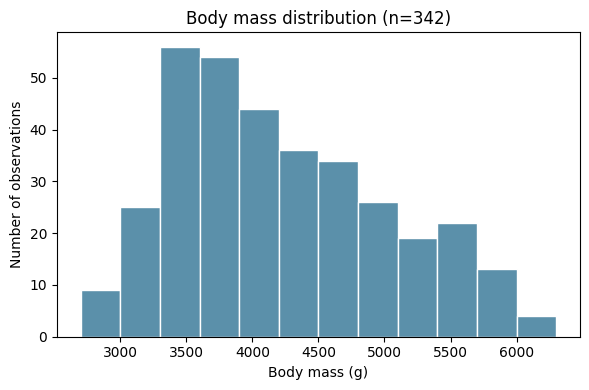

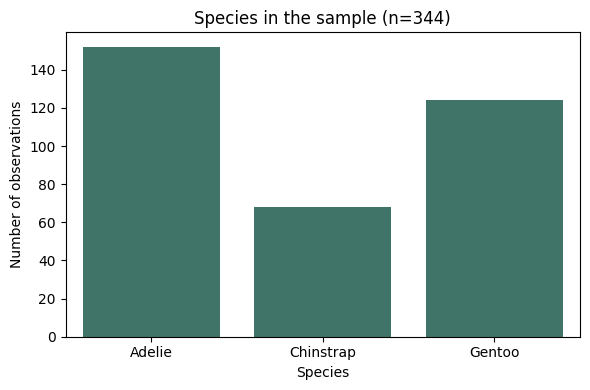

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot 1: Body mass distribution
mass = df["body_mass_g"].dropna()

plt.figure(figsize=(6, 4))
sns.histplot(x=mass, bins=12, color="#246B8E", edgecolor="white")
plt.title(f"Body mass distribution (n={len(mass)})")
plt.xlabel("Body mass (g)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

# Plot 2: Species counts
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="species", order=["Adelie", "Chinstrap", "Gentoo"], color="#387C6D")
plt.title(f"Species in the sample (n={df['species'].notna().sum()})")
plt.xlabel("Species")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

### Plots in a single window

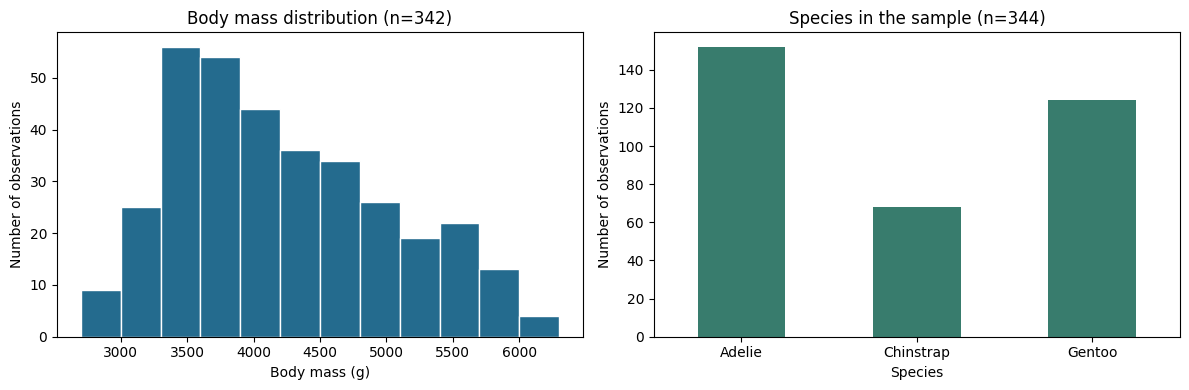

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
mass = df["body_mass_g"].dropna()
axes[0].hist(mass, bins=12, edgecolor="white", color="#246B8E")
axes[0].set(title=f"Body mass distribution (n={len(mass)})", xlabel="Body mass (g)", ylabel="Number of observations")

species_counts.reindex(["Adelie", "Chinstrap", "Gentoo"]).plot.bar(ax=axes[1], color="#387C6D", rot=0)
axes[1].set(title="Species in the sample (n=344)", xlabel="Species", ylabel="Number of observations")
plt.tight_layout()
plt.show()

## 6. Compare groups and relationships

Start by comparing body mass across species with a boxplot.

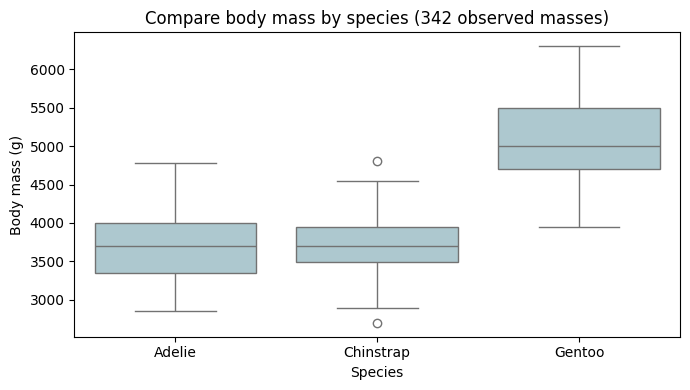

In [ ]:
group_summary = df.groupby("species")["body_mass_g"].agg(["size", "count", "mean", "median"]).round(2)

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="species", y="body_mass_g", order=["Adelie", "Chinstrap", "Gentoo"], color="#A7CBD5", ax=ax)
ax.set(title="Compare body mass by species (342 observed masses)", xlabel="Species", ylabel="Body mass (g)")
plt.tight_layout()
plt.show()

## 7. Investigate potential outliers

### Find outlier values

Inspect the Chinstrap body mass observations flagged by the boxplot, then compare pooled and within-species IQR rules. The final cell also checks for nonpositive measurements.

In [ ]:
mass = df.loc[df["species"] == "Chinstrap", "body_mass_g"]
q1, q3 = mass.quantile([0.25, 0.75])
iqr = q3 - q1

lower_fence = q1 - 1.5*iqr
upper_fence = q3 + 1.5*iqr

outliers = mass[(mass < lower_fence) | (mass > upper_fence)]
print(outliers)

313    4800.0
314    2700.0
Name: body_mass_g, dtype: float64


In [ ]:
mass.describe().round(2)

,body_mass_g
count,68.00
mean,3733.09
std,384.34
min,2700.00
25%,3487.50
50%,3700.00
75%,3950.00
max,4800.00


In [ ]:
q1 = df["body_mass_g"].quantile(0.25)
q3 = df["body_mass_g"].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
pooled_flag = (df["body_mass_g"] < lower) | (df["body_mass_g"] > upper)
print("Pooled body-mass fences (g):", lower, upper)
print("Pooled flags:", pooled_flag.sum())

Pooled body-mass fences (g): 1750.0 6550.0
Pooled flags: 0


In [ ]:
# transform returns each row's species-specific quartile.
by_species = df.groupby("species")["body_mass_g"]
group_q1 = by_species.transform(lambda values: values.quantile(0.25))
group_q3 = by_species.transform(lambda values: values.quantile(0.75))
group_iqr = group_q3 - group_q1
group_flag = ((df["body_mass_g"] < group_q1 - 1.5 * group_iqr) |
              (df["body_mass_g"] > group_q3 + 1.5 * group_iqr))
print("Within-species flags:", group_flag.sum())
print(df.loc[group_flag, ["species", "body_mass_g", "year"]].to_string())
print("Nonpositive observed measurements:", int((df[measurements] <= 0).sum().sum()))

Within-species flags: 2
       species  body_mass_g  year
313  Chinstrap       4800.0  2008
314  Chinstrap       2700.0  2008
Nonpositive observed measurements: 0


## 5. Explore sample composition and group summaries

Examine species across islands and sampling years, followed by species and gender counts and average measurements.

In [ ]:
print("Species by sampling island (counts):")
print(pd.crosstab(df["island"], df["species"]).to_string())
print("\nSampling-year counts:")
print(df["year"].value_counts().sort_index().to_string())

Species by sampling island (counts):
species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     124
Dream          56         68       0
Torgersen      52          0       0

Sampling-year counts:
year
2007    110
2008    114
2009    120


In [ ]:
# Species counts and percentages
print(df["species"].value_counts(), end="\n--------\n")
print(df["species"].value_counts(normalize=True).mul(100).round(2), end="\n--------\n")

# Gender counts within each species
print(pd.crosstab(df["species"], df["gender"]), end="\n--------\n")

# Average measurements by species and gender
print(df.groupby(["species", "gender"])[["body_mass_g", "flipper_length_mm"]].mean().round(2))

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
--------
species
Adelie       44.19
Gentoo       36.05
Chinstrap    19.77
Name: proportion, dtype: float64
--------
gender     female  male
species                
Adelie         73    73
Chinstrap      34    34
Gentoo         58    61
--------
                  body_mass_g  flipper_length_mm
species   gender                                
Adelie    female      3368.84             187.79
          male        4043.49             192.41
Chinstrap female      3527.21             191.74
          male        3938.97             199.91
Gentoo    female      4679.74             212.71
          male        5484.84             221.54


## 8. Explore measurement relationships

Inspect flipper length versus body mass and calculate overall correlations. Then examine summaries and Spearman correlations within each species.

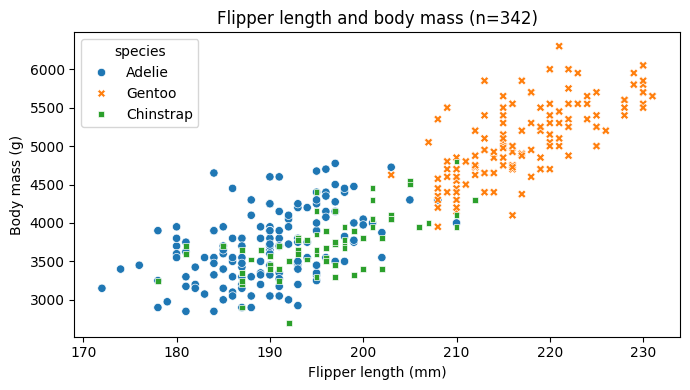

Pearson correlation: 0.871 | complete pairs: 342
0.8399741230312999


In [ ]:
# drop missing values only in the 2 plotted measurements
paired = df.dropna(subset=["flipper_length_mm", "body_mass_g"])

fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=paired, x="flipper_length_mm", y="body_mass_g", hue="species", style="species", ax=ax)
ax.set(title=f"Flipper length and body mass (n={len(paired)})", xlabel="Flipper length (mm)", ylabel="Body mass (g)")

plt.tight_layout()
plt.show()

correlation = paired["flipper_length_mm"].corr(paired["body_mass_g"])
print("Pearson correlation:", round(correlation, 3), "| complete pairs:", len(paired))
print(df["flipper_length_mm"].corr(df["body_mass_g"], method="spearman"))

In [ ]:
# Summary statistics by species
print(df.groupby("species")[["flipper_length_mm", "body_mass_g"]].agg(["count", "mean", "median", "std"]))
print("=============")

# Spearman correlation for each species
for species, group in df.groupby("species"):
    corr = group["flipper_length_mm"].corr(group["body_mass_g"], method="spearman")
    print(f"{species}: {corr:.3f}")

          flipper_length_mm                              body_mass_g  \
                      count        mean median       std       count   
species                                                                
Adelie                  151  189.953642  190.0  6.539457         151   
Chinstrap                68  195.823529  196.0  7.131894          68   
Gentoo                  123  217.186992  216.0  6.484976         123   

                                            
                  mean  median         std  
species                                     
Adelie     3700.662252  3700.0  458.566126  
Chinstrap  3733.088235  3700.0  384.335081  
Gentoo     5076.016260  5000.0  504.116237  
Adelie: 0.475
Chinstrap: 0.670
Gentoo: 0.717
